# Aerodynamics Assignment on Vortex Panel Method 
### BY: Naman Jain, SC26M013

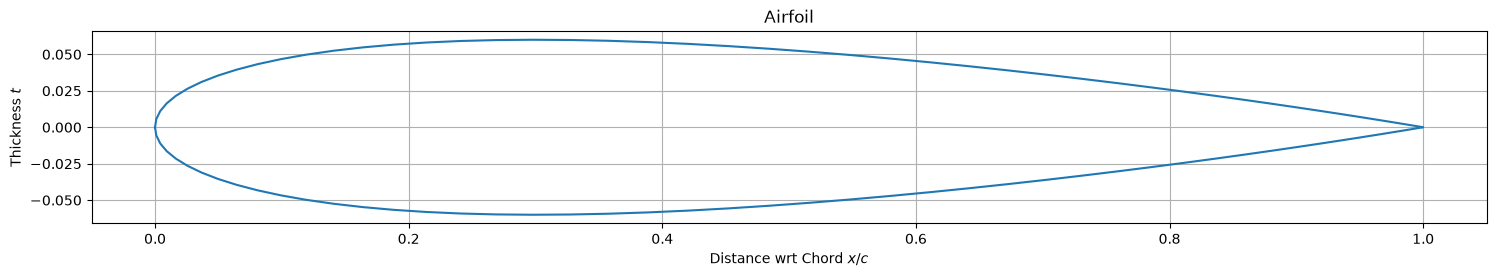

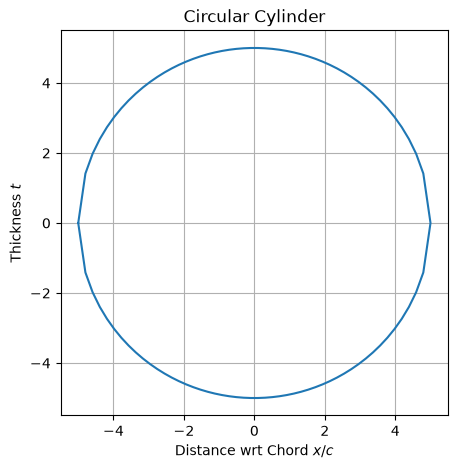

In [130]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Airfoil Plotting
a = 50 
beta = np.linspace(0, np.pi, a)
x = 0.5 * (1 - np.cos(beta))

m = 0 / 100       # Maximum Camber
p = 0 / 10        # Location of Maximum Camber
t = 12 / 100     # Maximum Thickness

V_inf = 10
alpha = 5
alpha_rad = np.deg2rad(alpha)

def airfoil_generation(x, m, p, t):
    x_u = np.zeros(len(x))
    x_l = np.zeros(len(x))
    y_u = np.zeros(len(x))
    y_l = np.zeros(len(x))
    y_t = np.zeros(len(x))
    y_c = np.zeros(len(x))
    dyc_dx = np.zeros(len(x))
    theta = np.zeros(len(x))

    
    #Original Airfoil Generation 
    if p == 0:
        for i in range(len(x)):
            y_t[i] = 5*t*(0.2969*(x[i]**0.5)        # Thickness distribution
                       - 0.1260*x[i]
                       - 0.3516*(x[i]**2)
                       + 0.2843*(x[i]**3)
                       - 0.1036*(x[i]**4))
            x_u[i] = x[i]  # Upper and lower surfaces
            x_l[i] = x[i] 
            y_u[i] = y_t[i]
            y_l[i] = - y_t[i]
    else:
        for i in range(len(x)):
            y_t[i] = 5*t*(0.2969*(x[i]**0.5)        # Thickness distribution
                       - 0.1260*x[i]
                       - 0.3516*(x[i]**2)
                       + 0.2843*(x[i]**3)
                       - 0.1036*(x[i]**4))
        
            if 0 <= x[i] <= p:                      # Camber line and slope
                y_c[i] = (m / p**2) * (2*p*x[i] - x[i]**2)
                dyc_dx[i] = (2*m / p**2) * (p - x[i])
        
            elif p < x[i] <= 1:
                y_c[i] = (m / (1-p)**2) * ((1 - 2*p) + 2*p*x[i] - x[i]**2)
                dyc_dx[i] = (2*m / (1-p)**2) * (p - x[i])
                
            theta[i] = np.arctan(dyc_dx[i])         # Angle of camber line
            
            x_u[i] = x[i] - y_t[i]*np.sin(theta[i]) # Upper and lower surfaces
            x_l[i] = x[i] + y_t[i]*np.sin(theta[i])
            y_u[i] = y_c[i] + y_t[i]*np.cos(theta[i])
            y_l[i] = y_c[i] - y_t[i]*np.cos(theta[i])

    x_u[0], y_u[0] = 0.0, 0.0
    x_l[0], y_l[0] = 0.0, 0.0

    x_u[-1], y_u[-1] = 1.0, 0.0
    x_l[-1], y_l[-1] = 1.0, 0.0
    
    # Combine upper and lower surfaces
    x_full = np.concatenate((x_u, x_l[-2:0:-1], [x_l[0]]))
    y_full = np.concatenate((y_u, y_l[-2:0:-1], [y_l[0]]))

    return x_full, y_full
    
def circular_cylinder(x, r):
    theta = np.linspace(0, 2*np.pi, N + 1)

    x_full = r * np.cos(theta)
    y_full = r * np.sin(theta)

    return x_full, y_full

f = airfoil_generation(x, m, p, t)

radius = 5
x3 = np.linspace(- radius, radius, a)
x_cylinder, y_cylinder = circular_cylinder(x3, radius)

plt.figure(figsize=(18, 2.5))
plt.plot(f[0], f[1])
plt.xlabel("Distance wrt Chord $x/c$")
plt.ylabel("Thickness $t$")
plt.title("Airfoil")
plt.grid(True)
plt.show()

plt.figure(figsize=(5, 5))
plt.plot(x_cylinder, y_cylinder)
plt.xlabel("Distance wrt Chord $x/c$")
plt.ylabel("Thickness $t$")
plt.title("Circular Cylinder")
plt.grid(True)
plt.show()


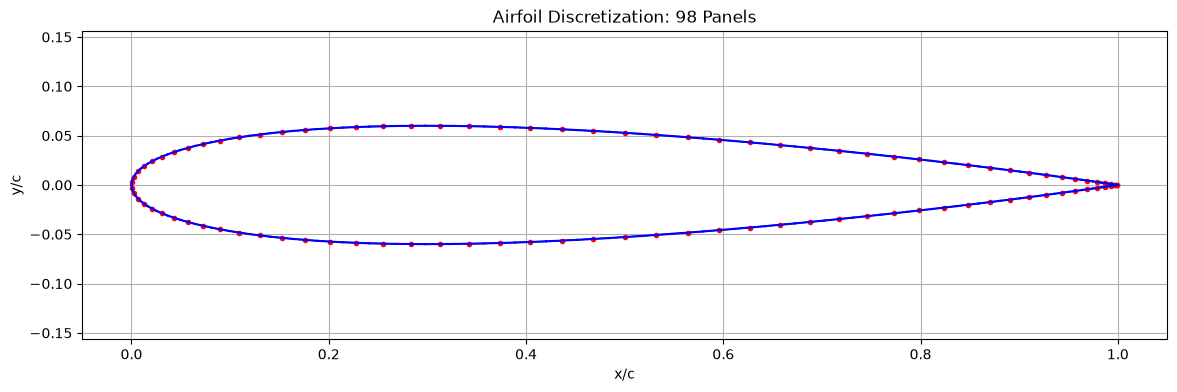

In [131]:
def panel_gen(x, y, V_inf, alpha_rad):
    x1 = x[:-1]
    y1 = y[:-1]
    x2 = x[1:]
    y2 = y[1:]

    N = len(x) - 1
    l = np.sqrt((x2 - x1)**2 + (y2 - y1)**2)
    
    x_c = (x1 + x2)/2
    y_c1 = (y1 + y2)/2

    theta_p = np.arctan2((y2 - y1),(x2 - x1))
    theta_p = np.mod(theta_p, 2 * np.pi)

    theta_final = theta_p + np.pi / 2
    beta  = theta_final - alpha_rad

    V_normal = V_inf * np.cos(beta)
    V_tangent = V_inf * np.sin(beta)
    
    return N, l, x_c, y_c1, theta_p, x1, x2, y1, y2, V_normal, V_tangent 

x_airfoil, y_airfoil = airfoil_generation(x, m, p, t)
N, l, x_c, y_c1, theta_p, x1, x2, y1, y2, V_normal, V_tangent = panel_gen(x_airfoil, y_airfoil, V_inf, alpha_rad)

# Plot panels and collocation points
plt.figure(figsize=(14, 4))
plt.plot(x_airfoil, y_airfoil, 'k-', linewidth=1)
plt.plot(x_c, y_c1, 'ro', markersize=3)

for i in range(N):
    plt.plot([x1[i], x2[i]], [y1[i], y2[i]], 'b-')
plt.axis('equal')
plt.xlabel('x/c')
plt.ylabel('y/c')
plt.title(f'Airfoil Discretization: {N} Panels')
plt.grid(True)
plt.show()

In [132]:
def JK_matrix(N, l, x_c, y_c1, theta_p, x1, x2, y1, y2):
    J = np.zeros((N, N))
    K = np.zeros((N, N))

    for i in range(N):
        tangent_vector0 = np.array([np.cos(theta_p[i]), np.sin(theta_p[i])])

        for j in range(N):
            if i == j:
                continue

            A_j = np.array([x1[j], y1[j]])
            P_i = np.array([x_c[i], y_c1[i]])

            tangent_vector1 = np.array([np.cos(theta_p[j]),np.sin(theta_p[j])])

            A = -np.dot(P_i - A_j, tangent_vector1)
            B = np.dot(P_i - A_j, P_i - A_j)
            Cn = -np.cos(theta_p[i] - theta_p[j])
            Ct = np.sin(theta_p[j] - theta_p[i])
            Dn = np.dot(P_i - A_j, tangent_vector0)
            Dt = ((P_i[0] - A_j[0]) * np.sin(theta_p[i]) - (P_i[1] - A_j[1]) * np.cos(theta_p[i]))
            E2 = B - A**2

            if E2 <= 1e-14:
                continue

            E = np.sqrt(E2)

            def dtheta_dn(s):
                n = (Cn * (A + s) + Dn - A * Cn) / ((A + s)**2 + E2)
                return n

            def dtheta_ds(s):
                t = (Ct * (A + s) + Dt - A * Ct) / ((A + s)**2 + E2)
                return t

            J[i, j] = quad(dtheta_dn, 0, l[j])[0]
            K[i, j] = quad(dtheta_ds, 0, l[j])[0]

    return J, K

def JK_linear(N, l, x_c, y_c1, theta_p, x1, x2):
    J1 = np.zeros((N, N+1))
    K1 = np.zeros((N, N+1))
    
    for i in range(N):
        for j in range(N):
            if i==j:
                J1[i, j] = J1[i, j] + 1.0
                J1[i, j+1] = J1[i, j + 1] - 1.0
                K1[i, j] = K1[i, j] + 1.0
                K1[i, j+1] = K1[i, j + 1] - 1.0
                continue

            def dtheta_dn(s):
                xj = x1[j] + s*np.cos(theta_p[j])
                yj = y1[j] + s*np.sin(theta_p[j])

                dx = x_c[i] - xj
                dy = y_c1[i] - yj
                n = (dx*np.cos(theta_p[i]) + dy*np.sin(theta_p[i])) / (dx**2 + dy**2)
                return n

            def dtheta_dt(s):
                xj = x1[j] + s*np.cos(theta_p[j])
                yj = y1[j] + s*np.sin(theta_p[j])

                dx = x_c[i] - xj
                dy = y_c1[i] - yj
                t = (dx*np.sin(theta_p[i]) - dy*np.cos(theta_p[i])) / (dx**2 + dy**2)
                return t
                
            def dtheta_linear(s):
                g = (s/l[j])*dtheta_dn(s)
                return g

            def dtheta_linear1(s):
                g = (s/l[j])*dtheta_dt(s)
                return g

            Jij = quad(dtheta_dn, 0, l[j])[0]
            Jpij = quad(dtheta_linear, 0, l[j])[0]
            J1[i, j] = J1[i, j] + Jij - Jpij
            J1[i, j+1] = J1[i, j+1] + Jpij

            Kij = quad(dtheta_dt, 0, l[j])[0]
            Kpij = quad(dtheta_linear1, 0, l[j])[0]
            K1[i, j] = K1[i, j] + Kij - Kpij
            K1[i, j+1] = K1[i, j+1] + Kpij

    return J1, K1
    
J, K = JK_matrix(N, l, x_c, y_c1, theta_p, x1, x2, y1, y2)
J1, K1 = JK_linear(N, l, x_c, y_c1, theta_p, x1, y1)

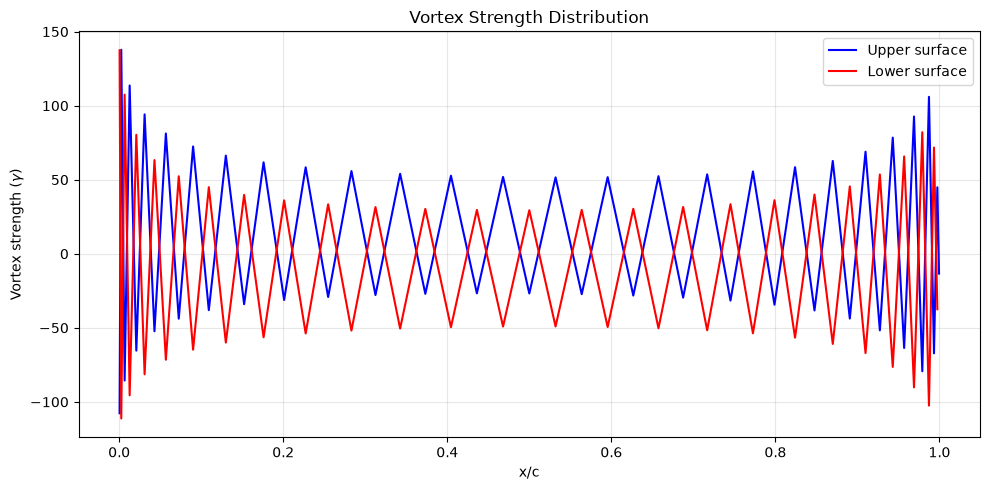

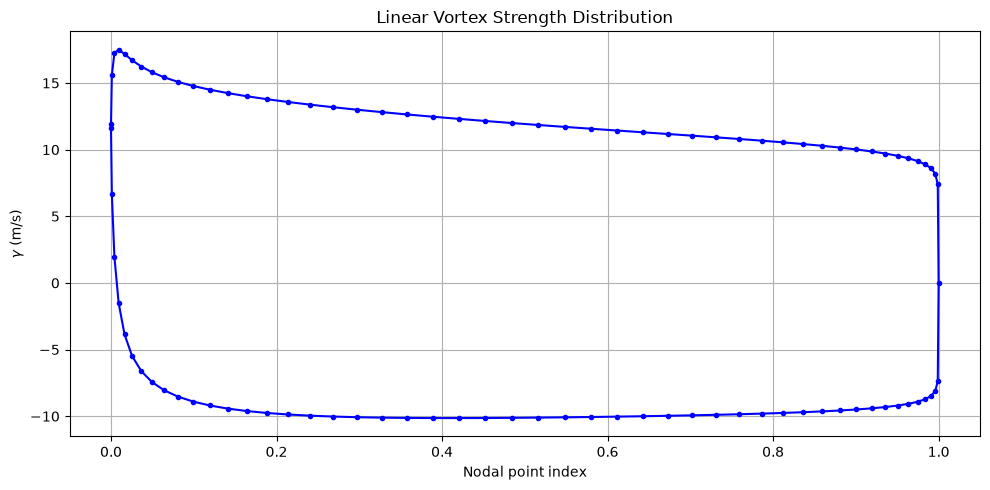

99


In [133]:
def vortex_panel_0(N, V_normal, J):
    A = np.zeros((N,N))
    b = np.zeros(N)
    A = J.copy()
    b =  2 * np.pi * V_normal

    # Kutta condition
    A[N//2, :] = 0.0
    A[N//2, N//2 + 1] = 1.0
    A[N//2, N//2] = 1.0

    b[N//2] = 0.0
    gamma = np.linalg.solve(A, b)

    return gamma, A, b

def vortex_panel_method1(N, J1, V_normal):
    M = np.zeros((N+1, N+1))
    RHS = np.zeros(N+1)

    M[:N,:] = J1
    RHS[:N] = 2 * np.pi * V_normal

    M[N, N//2] = 1
    RHS[N] = 0

    gamma_nodes = np.linalg.solve(M, RHS)

    return gamma_nodes, M, RHS
    
gamma, A, b = vortex_panel_0(N, V_normal, J)
gamma_nodes, M, RHS = vortex_panel_method1(N, J1, V_normal)
x_nodes = np.append(x1, x1[-1] + l[-1]*np.cos(theta_p[-1]))

plt.figure(figsize=(10, 5))
plt.plot(x_c[:N//2], gamma[:N//2 ], 'b-', label='Upper surface')
plt.plot(x_c[N//2 +1:], gamma[N//2 + 1:], 'r-', label='Lower surface')
plt.xlabel('x/c')
plt.ylabel('Vortex strength ($\gamma$)')
plt.title('Vortex Strength Distribution')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(x_nodes, gamma_nodes, 'b.-')
plt.xlabel("Nodal point index")
plt.ylabel(r"$\gamma$ (m/s)")
plt.title("Linear Vortex Strength Distribution")
plt.grid(True)
plt.tight_layout()
plt.show()

print(np.size(gamma_nodes))

The Coefficient of lift generated at 5 degrees by NACA 0012 is: 0.6027983179108504
The Coefficient of lift generated at 5 degrees by NACA 0012 is: 0.8590179019737822


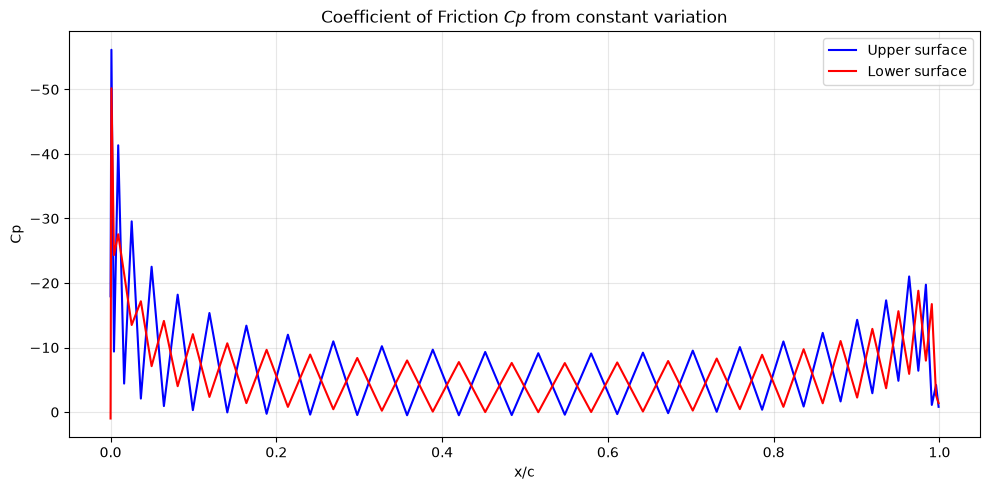

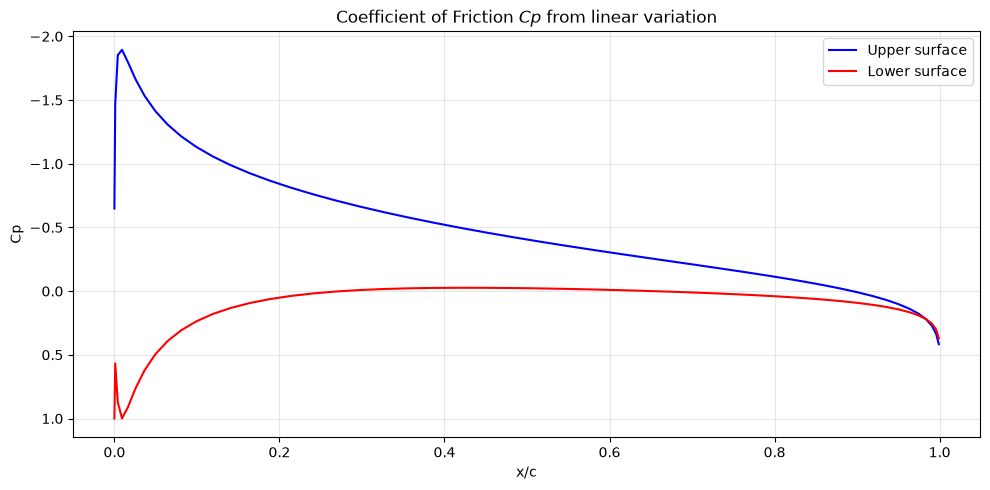

In [134]:
def pressure_coeff(N, K, V_tangent, gamma, V_inf):
    Vt = np.zeros(N +1)

    for i in range(N):
        induced_v = 0.0
        for j in range(N):
            induced_v = induced_v - gamma[j] * K[i, j] / (2*np.pi)
        Vt[i] = (V_tangent[i] + induced_v + gamma[i]/2)

    Cp = 1 - (Vt / V_inf)**2

    return Cp 

def lift_coeff(N, V_inf, gamma,gamma_nodes,  l):
    circulation = np.sum(0.5 * l * (gamma_nodes[:-1] + gamma_nodes[1:]))
    Cl_constant = 2 * np.sum(gamma * l) / V_inf
    total_circulation = np.sum(circulation)
    Cl = 2 * total_circulation / V_inf

    return Cl, Cl_constant

Cl = lift_coeff(N, V_inf, gamma, gamma_nodes, l)[0]
Cl1 = lift_coeff(N, V_inf, gamma, gamma_nodes, l)[1]
Cp = pressure_coeff(N, K, V_tangent, gamma, V_inf)
Cp1 = pressure_coeff(N, K1, V_tangent, gamma_nodes, V_inf)
print(f"The Coefficient of lift generated at {alpha} degrees by NACA {int(m*100)}{int(p*10)}{int(t*100)} is: {Cl}")
print(f"The Coefficient of lift generated at {alpha} degrees by NACA {int(m*100)}{int(p*10)}{int(t*100)} is: {Cl1}")

plt.figure(figsize=(10, 5))
plt.plot(x_nodes[:N//2], Cp[:N//2 ], 'b-', label='Upper surface')
plt.plot(x_nodes[N//2 +1:], Cp[N//2 + 1:], 'r-', label='Lower surface')
plt.xlabel('x/c')
plt.ylabel('Cp')
plt.title('Coefficient of Friction $Cp$ from constant variation')
plt.gca().invert_yaxis()
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(x_nodes[:N//2], Cp1[:N//2 ], 'b-', label='Upper surface')
plt.plot(x_nodes[N//2 +1:], Cp1[N//2 + 1:], 'r-', label='Lower surface')
plt.xlabel('x/c')
plt.ylabel('Cp')
plt.title('Coefficient of Friction $Cp$ from linear variation')
plt.gca().invert_yaxis()
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


NACA 0012

Number of panels:
[  5  15  25  35  45  55  65  75  85  95 105 115 125 135 145 155 165 175
 185 195]

Method 0 - Constant vortex:
Cl = [ 2.03570506  0.83114577  0.8141049   0.85776074  0.89517015  0.90246564
  2.13629559  2.17890138 -0.32127281  1.5264586   0.56169202  0.55908663
  0.94490482  0.7843022   0.71443312  0.80159989  0.82010428  0.75480044
  0.79264864  0.80597249]
Error (%) = [270.12819317  51.11741327  48.01907272  55.95649793  62.7582092
  64.08466234 288.41737912 296.16388751 158.41323895 177.53792681
   2.12582137   1.65211538  71.80087632  42.60039929  29.89693149
  45.74543393  49.10986992  37.2364442   44.11793529  46.54045358]

Method 1 - Linear vortex:
Cl = [0.5798317  0.60044127 0.60211734 0.60256551 0.6027463  0.60283659
 0.60288802 0.60292003 0.60294129 0.60295612 0.60296686 0.6029749
 0.60298106 0.60298589 0.60298975 0.60299287 0.60299544 0.60299757
 0.60299937 0.60300089]
Error (%) = [5.42394583 9.17113982 9.47587951 9.55736472 9.59023594 9.606653

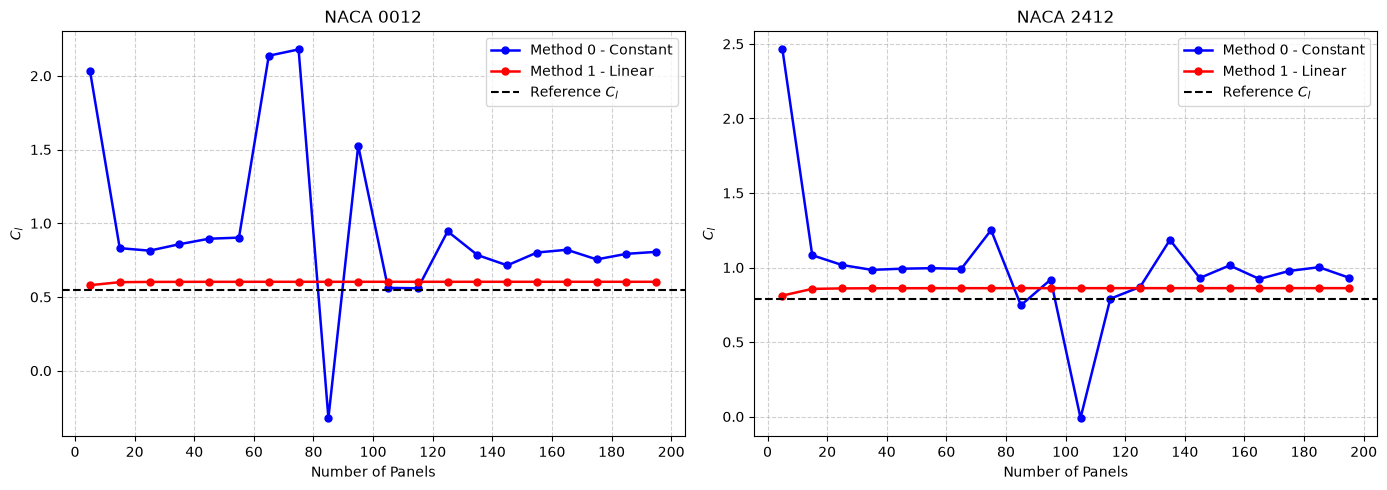

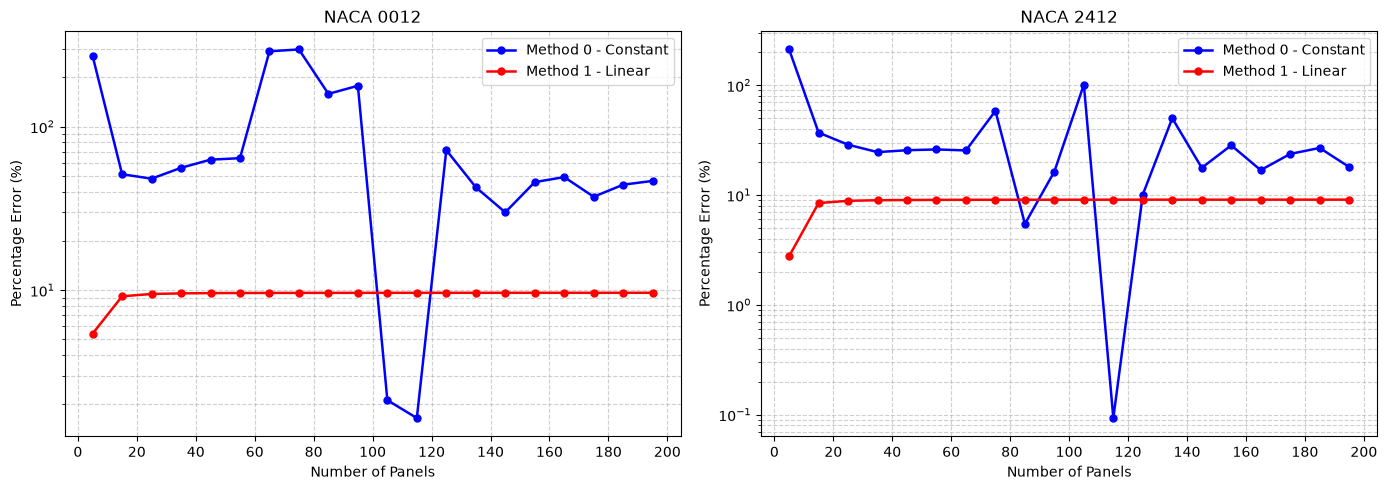

In [137]:
Cl_2412 = 0.79
Cl_0012 = 0.55
Cl_ref = [Cl_0012, Cl_2412]

airfoil_names = ['NACA 0012', 'NACA 2412']

V_inf = 10
alpha = 5
alpha_rad = np.deg2rad(alpha)

N_panels = np.arange(5, 201, 10)
n_cases = len(N_panels)

m = [0/100, 2/100]
p = [0/10, 4/10]
t = [12/100, 12/100]

Cl = np.zeros((len(N_panels), 2, 2))
Error = np.zeros_like(Cl)

for i, N_target in enumerate(N_panels):
    beta = np.linspace(0, np.pi, N_target)
    x = 0.5 * (1 - np.cos(beta))

    for k in range(2):
        x_full, y_full = airfoil_generation(x, m[k], p[k], t[k])

        N, l, x_c, y_c1, theta_p, x1, x2, y1, y2, V_normal, V_tangent = panel_gen(
            x_full, y_full, V_inf, alpha_rad
        )

        J, K = JK_matrix(N, l, x_c, y_c1, theta_p, x1, x2, y1, y2)
        gamma, A, b = vortex_panel_0(N, V_normal, J)

        J1, K1 = JK_linear(N, l, x_c, y_c1, theta_p, x1, y1)
        gamma_nodes, M, RHS = vortex_panel_method1(N, J1, V_normal)

        Cl[i, k, 1], Cl[i, k, 0] = lift_coeff(
            N, V_inf, gamma, gamma_nodes, l
        )

        Error[i, k, :] = np.abs(Cl[i, k, :] - Cl_ref[k]) / abs(Cl_ref[k]) * 100
for k in range(2):

    print("\n====================================")
    print(airfoil_names[k])
    print("====================================")

    print("\nNumber of panels:")
    print(N_panels)

    print("\nMethod 0 - Constant vortex:")
    print("Cl =", Cl[:, k, 0])
    print("Error (%) =", Error[:, k, 0])

    print("\nMethod 1 - Linear vortex:")
    print("Cl =", Cl[:, k, 1])
    print("Error (%) =", Error[:, k, 1])

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for k in range(2):
    ax[k].plot(N_panels, Cl[:, k, 0],'bo-', linewidth=1.8,markersize=5,label='Method 0 - Constant')
    ax[k].plot(N_panels, Cl[:, k, 1],'ro-', linewidth=1.8,markersize=5,label='Method 1 - Linear')
    ax[k].axhline(Cl_ref[k],color='black',linestyle='--',label='Reference $C_l$')
    ax[k].set_title(airfoil_names[k])
    ax[k].set_xlabel('Number of Panels')
    ax[k].set_ylabel(r'$C_l$')
    ax[k].set_xticks(np.arange(0, 201, 20))
    ax[k].grid(True, linestyle='--', alpha=0.6)
    ax[k].legend()

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for k in range(2):
    ax[k].plot( N_panels, Error[:, k, 0], 'bo-', linewidth=1.8, markersize=5,label='Method 0 - Constant')
    ax[k].plot(N_panels, Error[:, k, 1],'ro-', linewidth=1.8,markersize=5,label='Method 1 - Linear')
    ax[k].set_title(airfoil_names[k])
    ax[k].set_xlabel('Number of Panels')
    ax[k].set_ylabel('Percentage Error (%)')
    ax[k].set_xticks(np.arange(0, 201, 20))
    ax[k].set_yscale('log')
    ax[k].grid(True, which='both', linestyle='--', alpha=0.6)
    ax[k].legend()

plt.tight_layout()
plt.show()

In [143]:
alpha_rad1 = np.deg2rad(np.arange(15))
alpha_deg = np.rad2deg(alpha_rad1)

a1 = 350
beta = np.linspace(0, np.pi, a1)
x5 = 0.5 * (1 - np.cos(beta))
Xc = np.zeros((2, N+1))

m = [0 / 100, 2/100]     
p = [0 / 10 , 4/10]       
t = [12 / 100, 12/100] 

Cl = np.zeros((2, len(alpha_rad1), 2))
Cm = np.zeros((2, len(alpha_rad1), 2))
Cp = np.zeros((2, len(alpha_rad1), 2*a1 - 1))

n_airfoils = len(m)
n_alpha = len(alpha_deg)

n_nodes = 2*a1 - 1
n_panels = n_nodes - 1

Cl = np.zeros((n_airfoils, n_alpha, 2))
Cm = np.zeros((n_airfoils, n_alpha, 2))
Cp = np.zeros((n_airfoils, n_alpha, n_nodes))

Xc = np.zeros((n_airfoils, n_nodes))

for i in range(n_airfoils):
    x_full, y_full = airfoil_generation(x5, m[i], p[i], t[i])
    Xc[i, :] = x_full
    for j in range(n_alpha):
        N, l, x_c, y_c1, theta_p, x1, x2, y1, y2, V_normal, V_tangent = panel_gen(x_full, y_full, V_inf, alpha_rad1[j])
        J, K = JK_matrix(N, l, x_c, y_c1, theta_p, x1, x2, y1, y2)
        J1, K1 = JK_linear(N, l, x_c, y_c1, theta_p, x1, y1)
        gamma, A, b = vortex_panel_0(N, V_normal, J)
        gamma_nodes, M, RHS = vortex_panel_method1(N, J1, V_normal)
        Cl[i, j, 1],Cl[i, j, 0] = lift_coeff(N, V_inf, gamma,gamma_nodes, l)
        Cm[i, j, 0] = - Cl[i, j, 0] / 4
        Cm[i, j, 1] = - Cl[i, j, 1] / 4
        Cp[i, j, :] = pressure_coeff(N, K1, V_tangent, gamma_nodes, V_inf)

print("Symmetric airfoil - Constant:", Cl[0, :, 0])
print("Symmetric airfoil - Linear:", Cl[0, :, 1])

print("Asymmetric airfoil - Constant:", Cl[1, :, 0])
print("Asymmetric airfoil - Linear:", Cl[1, :, 1])

Symmetric airfoil - Constant: [0.14831819 0.26917971 0.38995924 0.51061999 0.63112519 0.75143815
 0.87152221 0.9913408  1.11085742 1.23003566 1.34883921 1.4672319
 1.58517766 1.70264055 1.81958481]
Symmetric airfoil - Linear: [-3.19744231e-15  1.20749132e-01  2.41461482e-01  3.62100281e-01
  4.82628781e-01  6.03010267e-01  7.23208071e-01  8.43185578e-01
  9.62906243e-01  1.08233360e+00  1.20143126e+00  1.32016296e+00
  1.43849252e+00  1.55638391e+00  1.67380120e+00]
Asymmetric airfoil - Constant: [0.27986316 0.40077167 0.52155809 0.64218564 0.76261758 0.88281721
 1.00274793 1.1223732  1.24165659 1.36056176 1.47905249 1.59709268
 1.71464638 1.83167779 1.94815125]
Asymmetric airfoil - Linear: [0.25962328 0.38034059 0.50094204 0.62139091 0.74165049 0.86168416
 0.98145535 1.10092758 1.22006445 1.33882968 1.4571871  1.57510064
 1.69253438 1.80945257 1.92581958]


NACA 0012 - Thin Airfoil Theory: [0.         0.10966227 0.21932454 0.32898681 0.43864908 0.54831136
 0.65797363 0.7676359  0.87729817 0.98696044 1.09662271 1.20628498
 1.31594725 1.42560952 1.5352718 ]
NACA 2412 - Thin Airfoil Theory: [0.22776854 0.33743081 0.44709308 0.55675535 0.66641762 0.77607989
 0.88574216 0.99540443 1.10506671 1.21472898 1.32439125 1.43405352
 1.54371579 1.65337806 1.76304033]
Symmetric airfoil - Constant: [0.14831819 0.26917971 0.38995924 0.51061999 0.63112519 0.75143815
 0.87152221 0.9913408  1.11085742 1.23003566 1.34883921 1.4672319
 1.58517766 1.70264055 1.81958481]
Symmetric airfoil - Linear: [-3.19744231e-15  1.20749132e-01  2.41461482e-01  3.62100281e-01
  4.82628781e-01  6.03010267e-01  7.23208071e-01  8.43185578e-01
  9.62906243e-01  1.08233360e+00  1.20143126e+00  1.32016296e+00
  1.43849252e+00  1.55638391e+00  1.67380120e+00]
Cambered airfoil - Constant: [0.27986316 0.40077167 0.52155809 0.64218564 0.76261758 0.88281721
 1.00274793 1.1223732  1.2416

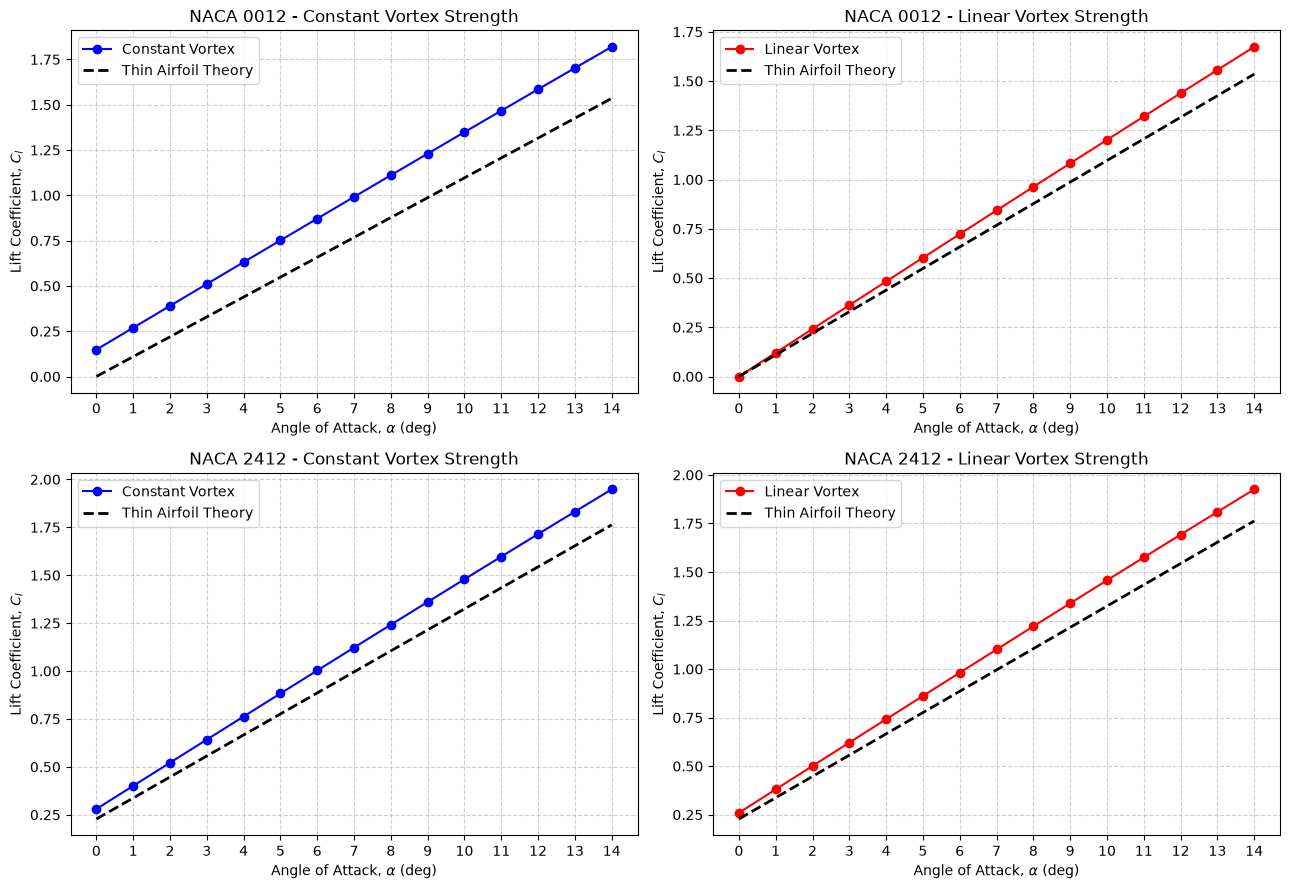

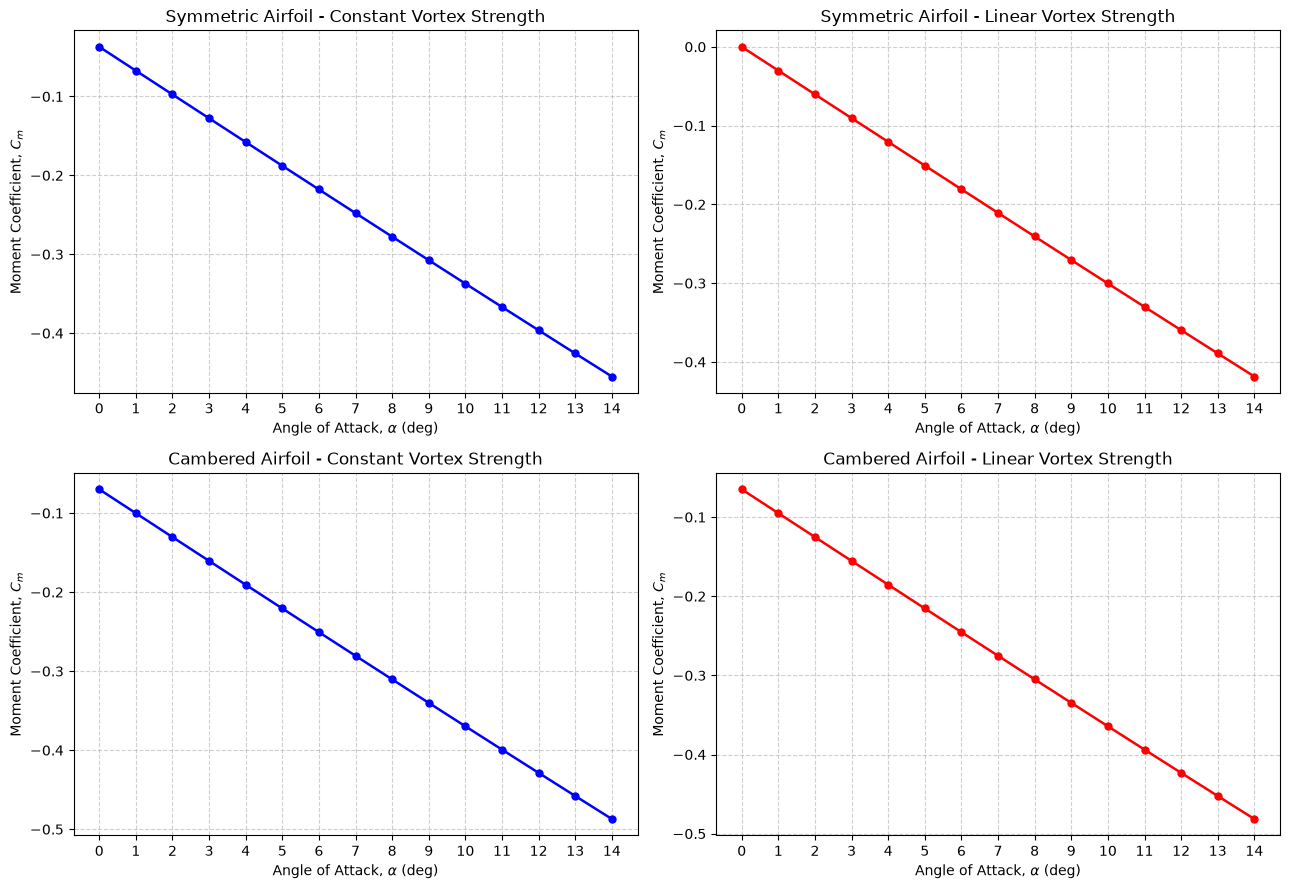

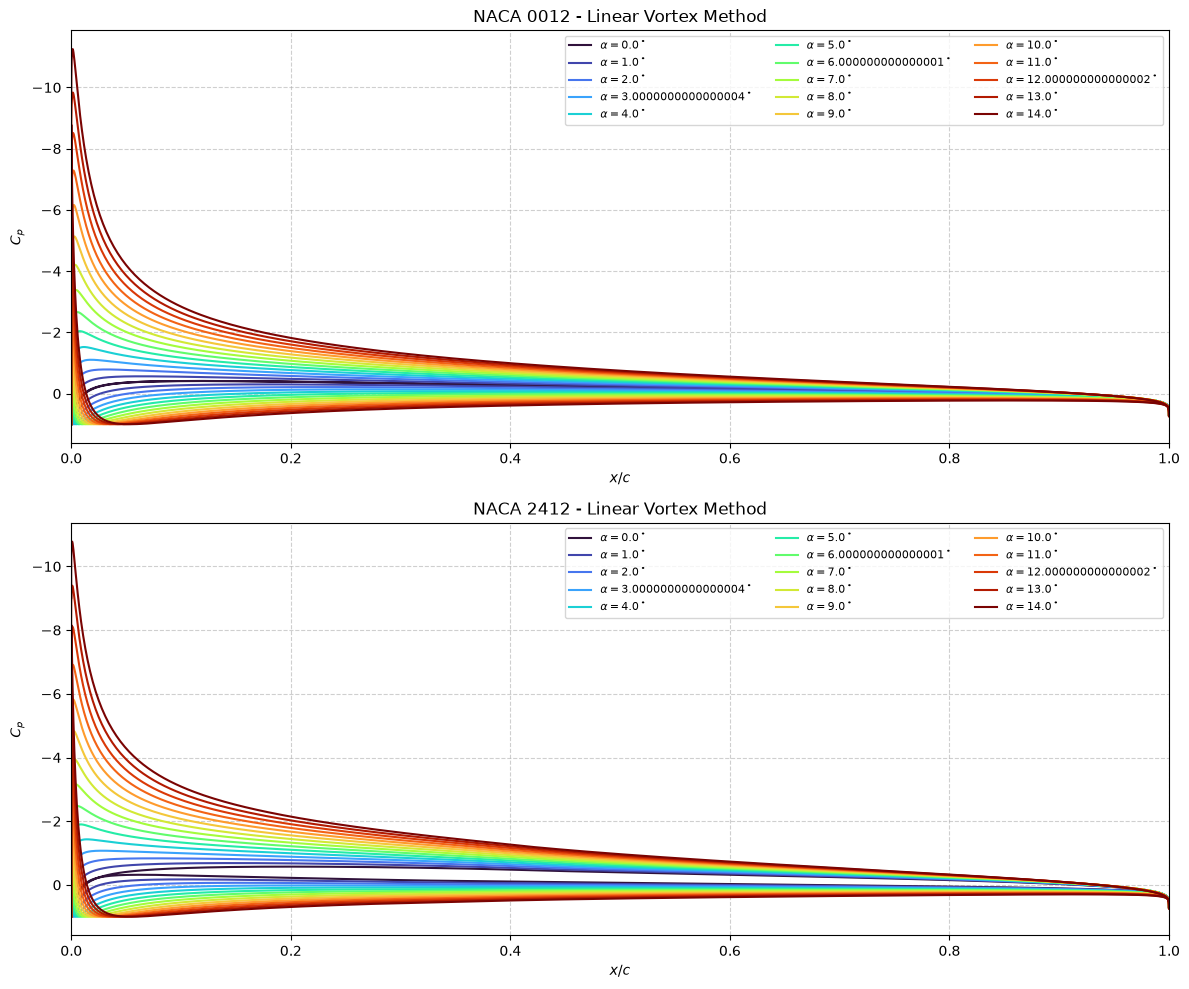

In [144]:
Cl_exact = np.zeros((2, n_alpha))

Cl_exact[0, :] = 2 * np.pi * np.deg2rad(alpha_deg)
Cl_exact[1, :] = 2 * np.pi * np.deg2rad(alpha_deg + 2.077)

print("NACA 0012 - Thin Airfoil Theory:", Cl_exact[0, :])
print("NACA 2412 - Thin Airfoil Theory:", Cl_exact[1, :])

print("Symmetric airfoil - Constant:", Cl[0, :, 0])
print("Symmetric airfoil - Linear:", Cl[0, :, 1])

print("Cambered airfoil - Constant:", Cl[1, :, 0])
print("Cambered airfoil - Linear:", Cl[1, :, 1])

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
ax[0, 0].plot(alpha_deg, Cl[0, :, 0], 'bo-', label='Constant Vortex')
ax[0, 0].plot(alpha_deg, Cl_exact[0], 'k--', linewidth=2, label='Thin Airfoil Theory')
ax[0, 0].set_title('NACA 0012 - Constant Vortex Strength')

ax[0, 1].plot(alpha_deg, Cl[0, :, 1], 'ro-', label='Linear Vortex')
ax[0, 1].plot(alpha_deg, Cl_exact[0], 'k--', linewidth=2, label='Thin Airfoil Theory')
ax[0, 1].set_title('NACA 0012 - Linear Vortex Strength')

ax[1, 0].plot(alpha_deg, Cl[1, :, 0], 'bo-', label='Constant Vortex')
ax[1, 0].plot(alpha_deg, Cl_exact[1], 'k--', linewidth=2, label='Thin Airfoil Theory')
ax[1, 0].set_title('NACA 2412 - Constant Vortex Strength')

ax[1, 1].plot(alpha_deg, Cl[1, :, 1], 'ro-', label='Linear Vortex')
ax[1, 1].plot(alpha_deg, Cl_exact[1], 'k--', linewidth=2, label='Thin Airfoil Theory')
ax[1, 1].set_title('NACA 2412 - Linear Vortex Strength')

for a in ax.flat:
    a.set_xlabel(r'Angle of Attack, $\alpha$ (deg)')
    a.set_ylabel(r'Lift Coefficient, $C_l$')
    a.set_xticks(np.arange(0, 15, 1))
    a.grid(True, linestyle='--', alpha=0.6)
    a.legend()

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(2, 2, figsize=(13, 9))

ax[0, 0].plot(alpha_deg, Cm[0, :, 0], 'bo-', linewidth=1.8, markersize=5)
ax[0, 0].set_title('Symmetric Airfoil - Constant Vortex Strength')

ax[0, 1].plot(alpha_deg, Cm[0, :, 1], 'ro-', linewidth=1.8, markersize=5)
ax[0, 1].set_title('Symmetric Airfoil - Linear Vortex Strength')

ax[1, 0].plot(alpha_deg, Cm[1, :, 0], 'bo-', linewidth=1.8, markersize=5)
ax[1, 0].set_title('Cambered Airfoil - Constant Vortex Strength')

ax[1, 1].plot(alpha_deg, Cm[1, :, 1], 'ro-', linewidth=1.8, markersize=5)
ax[1, 1].set_title('Cambered Airfoil - Linear Vortex Strength')

for a in ax.flat:
    a.set_xlabel(r'Angle of Attack, $\alpha$ (deg)')
    a.set_ylabel(r'Moment Coefficient, $C_m$')
    a.set_xticks(np.arange(0, 15, 1))
    a.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(2, 1, figsize=(12, 10))
colors = plt.cm.turbo(np.linspace(0, 1, n_alpha))

for j in range(n_alpha):
    ax[0].plot(Xc[0, :], Cp[0, j, :], color=colors[j],
               linewidth=1.5, label=fr'$\alpha={alpha_deg[j]}^\circ$')

    ax[1].plot(Xc[1, :], Cp[1, j, :], color=colors[j],
               linewidth=1.5, label=fr'$\alpha={alpha_deg[j]}^\circ$')

ax[0].set_title('NACA 0012 - Linear Vortex Method')
ax[1].set_title('NACA 2412 - Linear Vortex Method')

for a in ax:
    a.set_xlabel(r'$x/c$')
    a.set_ylabel(r'$C_p$')
    a.set_xlim(0, 1)
    a.invert_yaxis()
    a.grid(True, linestyle='--', alpha=0.6)
    a.legend(ncol=3, fontsize=8, loc='best')

plt.tight_layout()
plt.show()